# Multimodal — Pencarian Gambar ↔ Teks dengan CLIP (tanpa latih)
**Kapan dipakai:** cari foto dari kalimat ("sepatu merah"), cari foto yang mirip, atau beri
label/tag otomatis tanpa data latih.

**Idenya:** CLIP mengubah gambar DAN teks jadi vektor di ruang yang sama. Vektor dinormalkan
(panjang 1), jadi perkalian titik = kemiripan cosine. Makin besar = makin cocok.

**Langkah:**
1. Embedding semua gambar galeri, gambar query, dan kalimat nama kelas.
2. Kalimat bebas → gambar, gambar → label (zero-shot), gambar → gambar mirip.
3. Simpan top-5 gambar mirip dan label tiap query.

**Data demo:** CIFAR-10 kecil, galeri = train, query = test. `clip_b32` hanya paham bahasa
**Inggris**: terjemahkan kalimat Indonesia dulu.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.nn import functional
from transformers import CLIPModel, CLIPProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/classification"   # GANTI saat lomba
DATA_FOLDER = f"{DATA_FOLDER}/cifar10_small"
GALLERY_CSV = f"{DATA_FOLDER}/train.csv"
QUERY_CSV = f"{DATA_FOLDER}/test.csv"
QUERY_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
CLIP_FOLDER = "../../../pretrained/clip_b32"

ID_COL = "id"
PATH_COL = "path"       # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"        # label galeri, dipakai untuk daftar nama kelas
TEMPLATE = "a photo of a {}"
# TEMPLATE = "a low-resolution photo of a {}"    # cocok untuk gambar kecil/buram
SEARCH_SENTENCES = ["a red car", "a ship on the sea", "an animal with antlers"]
TOP_K = 5
BATCH_SIZE = 64
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
gallery = pd.read_csv(GALLERY_CSV)
query = pd.read_csv(QUERY_CSV)
class_names = sorted(gallery[TARGET].unique())
print("galeri:", gallery.shape, "| query:", query.shape)
print(class_names)
gallery.head()

galeri: (4000, 2) | query: (1000, 2)
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane
3,train/airplane/0003.png,airplane
4,train/airplane/0004.png,airplane


## Langkah 1a — model CLIP + embedding gambar

In [4]:
model = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
model.eval()
model = model.to(DEVICE)
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)


def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = []
        for path in paths[start:start + BATCH_SIZE]:
            images.append(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB"))
        inputs = processor(images=images, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            output = model.get_image_features(**inputs)
        batches.append(output.pooler_output.cpu())
    return functional.normalize(torch.cat(batches), dim=-1).numpy()


# coba pada 2 gambar pertama
print(embed_images(list(gallery[PATH_COL][:2])).shape)

gallery_vectors = embed_images(list(gallery[PATH_COL]))
query_vectors = embed_images(list(query[PATH_COL]))
print("galeri:", gallery_vectors.shape, "| query:", query_vectors.shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

(2, 512)


galeri: (4000, 512) | query: (1000, 512)


## Langkah 1b — embedding teks

In [5]:
def embed_texts(sentences):
    inputs = processor(text=sentences, return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        output = model.get_text_features(**inputs)
    return functional.normalize(output.pooler_output.cpu(), dim=-1).numpy()


class_sentences = []
for name in class_names:
    class_sentences.append(TEMPLATE.format(name))
class_vectors = embed_texts(class_sentences)
print(class_sentences[:3], class_vectors.shape)

['a photo of a airplane', 'a photo of a automobile', 'a photo of a bird'] (10, 512)


## Langkah 2a — kalimat bebas → gambar
Ganti isi `SEARCH_SENTENCES` di Konfigurasi.

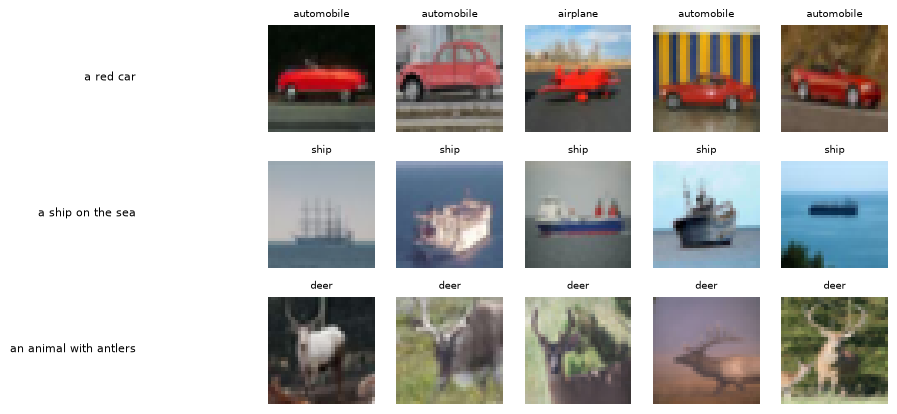

In [6]:
search_scores = embed_texts(SEARCH_SENTENCES) @ gallery_vectors.T
fig, axes = plt.subplots(len(SEARCH_SENTENCES), TOP_K, figsize=(8, 5))
for i in range(len(SEARCH_SENTENCES)):
    best_rows = np.argsort(-search_scores[i])[:TOP_K]
    for column in range(TOP_K):
        row = best_rows[column]
        axes[i, column].imshow(Image.open(f"{DATA_FOLDER}/{gallery[PATH_COL][row]}"))
        axes[i, column].set_title(gallery[TARGET][row], fontsize=7)
        axes[i, column].axis("off")
    axes[i, 0].text(-40, 16, SEARCH_SENTENCES[i], fontsize=8, ha="right")
plt.show()

## Langkah 2b — gambar → label (zero-shot) dan gambar → gambar mirip

In [7]:
label_scores = query_vectors @ class_vectors.T            # (jumlah query, jumlah kelas)
predictions = np.array(class_names)[label_scores.argmax(axis=1)]

image_scores = query_vectors @ gallery_vectors.T           # (jumlah query, jumlah galeri)
top_rows = np.argsort(-image_scores, axis=1)[:, :TOP_K]   # TOP_K galeri termirip per query
print(predictions[:5])
print(top_rows[:2])

['airplane' 'airplane' 'airplane' 'airplane' 'airplane']
[[3823  266   69  101 3809]
 [ 309    1  216  162  353]]


## Langkah 3 — simpan hasil
`top_gallery` = path gambar galeri termirip, dipisah spasi.

In [8]:
top_texts = []
for rows in top_rows:
    top_texts.append(" ".join(gallery[PATH_COL].iloc[rows]))

submission = pd.DataFrame()
submission["id"] = query[ID_COL]
submission["top_gallery"] = top_texts
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,top_gallery,label
0,1,train/truck/0223.png train/airplane/0266.png t...,airplane
1,2,train/airplane/0309.png train/airplane/0001.pn...,airplane
2,3,train/airplane/0052.png train/airplane/0026.pn...,airplane
3,4,train/airplane/0140.png train/airplane/0225.pn...,airplane
4,5,train/airplane/0268.png train/airplane/0185.pn...,airplane


## Cek dengan kunci jawaban (HAPUS saat lomba)
Akurasi zero-shot = label tebakan benar. Recall@k = query yang punya minimal satu gambar
berlabel sama di top-k. Precision@k = porsi gambar berlabel sama di top-k.

In [9]:
query_truth = pd.read_csv(QUERY_KEY_CSV)[TARGET].to_numpy()
print("akurasi zero-shot:", round((predictions == query_truth).mean(), 4))

top_labels = gallery[TARGET].to_numpy()[top_rows]
is_same = top_labels == query_truth[:, None]
print(f"Recall@{TOP_K}:", round(is_same.any(axis=1).mean(), 4))
print(f"Precision@{TOP_K}:", round(is_same.mean(), 4))

akurasi zero-shot: 0.881
Recall@5: 0.964
Precision@5: 0.858
